# Import Relavent Libraries

In [1]:
!pip install xgboost

Defaulting to user installation because normal site-packages is not writeable


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor

import xgboost
from xgboost import XGBRegressor

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings('ignore')

# Load the dataset

In [3]:
df = pd.read_csv('USA_Housing.csv')
df.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05,USNS Raymond\nFPO AE 09386


# Steps:

- Basic EDA
    - Missing Data
    - Duplicate Data
    - Outliers or Anomalies
    - Data Visualization
    - Feature Encoding
    - Feature Selection
    

- Model Building
    - Seprate your Independent and Dependent data
    - Data Splitting
    - Model Selection
    - Model Training
    - Model Evaluation

# Basic EDA

In [4]:
df.head(3)

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."


In [5]:
df.shape

(5000, 7)

In [6]:
df.columns

Index(['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms',
       'Avg. Area Number of Bedrooms', 'Area Population', 'Price', 'Address'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Avg. Area Income              5000 non-null   float64
 1   Avg. Area House Age           5000 non-null   float64
 2   Avg. Area Number of Rooms     5000 non-null   float64
 3   Avg. Area Number of Bedrooms  5000 non-null   float64
 4   Area Population               5000 non-null   float64
 5   Price                         5000 non-null   float64
 6   Address                       5000 non-null   object 
dtypes: float64(6), object(1)
memory usage: 273.6+ KB


In [8]:
df.describe()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5.000000e+03
mean,68583.108984,5.977222,6.987792,3.981330,36163.516039,1.232073e+06
std,10657.991214,0.991456,1.005833,1.234137,9925.650114,3.531176e+05
min,17796.631190,2.644304,3.236194,2.000000,172.610686,1.593866e+04
25%,61480.562388,5.322283,6.299250,3.140000,29403.928702,9.975771e+05
50%,68804.286404,5.970429,7.002902,4.050000,36199.406689,1.232669e+06
75%,75783.338666,6.650808,7.665871,4.490000,42861.290769,1.471210e+06
max,107701.748378,9.519088,10.759588,6.500000,69621.713378,2.469066e+06


In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Avg. Area Income,5000.0,6.858311e+04,10657.991214,17796.631190,61480.562388,6.880429e+04,7.578334e+04,1.077017e+05
Avg. Area House Age,5000.0,5.977222e+00,0.991456,2.644304,5.322283,5.970429e+00,6.650808e+00,9.519088e+00
Avg. Area Number of Rooms,5000.0,6.987792e+00,1.005833,3.236194,6.299250,7.002902e+00,7.665871e+00,1.075959e+01
Avg. Area Number of Bedrooms,5000.0,3.981330e+00,1.234137,2.000000,3.140000,4.050000e+00,4.490000e+00,6.500000e+00
Area Population,5000.0,3.616352e+04,9925.650114,172.610686,29403.928702,3.619941e+04,4.286129e+04,6.962171e+04
Price,5000.0,1.232073e+06,353117.626581,15938.657923,997577.135049,1.232669e+06,1.471210e+06,2.469066e+06


In [10]:
df['Price']

0       1.059034e+06
1       1.505891e+06
2       1.058988e+06
3       1.260617e+06
4       6.309435e+05
            ...     
4995    1.060194e+06
4996    1.482618e+06
4997    1.030730e+06
4998    1.198657e+06
4999    1.298950e+06
Name: Price, Length: 5000, dtype: float64

In [11]:
df.Price.value_counts()

Price
1.059034e+06    1
1.521141e+06    1
1.148372e+06    1
2.065710e+06    1
1.749820e+06    1
               ..
1.444701e+06    1
7.884278e+05    1
8.759045e+05    1
9.844212e+05    1
1.298950e+06    1
Name: count, Length: 5000, dtype: int64

In [12]:
df.nunique()

Avg. Area Income                5000
Avg. Area House Age             5000
Avg. Area Number of Rooms       5000
Avg. Area Number of Bedrooms     255
Area Population                 5000
Price                           5000
Address                         5000
dtype: int64

In [13]:
df['Avg. Area Number of Bedrooms'].unique()

array([4.09, 3.09, 5.13, 3.26, 4.23, 4.04, 3.41, 2.42, 2.3 , 6.1 , 4.1 ,
       4.49, 3.1 , 2.27, 4.37, 4.01, 3.12, 4.3 , 5.12, 5.49, 4.07, 2.1 ,
       4.31, 6.34, 4.33, 2.03, 4.  , 3.04, 3.24, 4.42, 5.36, 6.29, 6.  ,
       2.07, 3.01, 2.39, 2.5 , 2.17, 6.3 , 4.43, 4.44, 6.32, 3.18, 6.35,
       3.22, 2.13, 4.02, 6.36, 3.32, 4.12, 6.41, 5.08, 3.06, 2.28, 4.2 ,
       4.32, 5.43, 3.13, 3.28, 3.27, 3.08, 3.17, 3.15, 6.25, 3.43, 4.38,
       6.16, 4.28, 4.11, 6.24, 3.35, 4.48, 3.2 , 3.07, 3.39, 3.38, 6.06,
       3.3 , 3.46, 3.33, 4.41, 2.38, 2.37, 3.45, 2.02, 2.14, 2.23, 2.44,
       2.29, 4.19, 6.04, 5.28, 5.1 , 5.45, 4.36, 2.05, 6.39, 4.45, 4.22,
       6.44, 4.35, 3.37, 6.2 , 6.19, 2.49, 2.04, 4.46, 5.15, 3.21, 6.45,
       3.44, 2.18, 3.49, 6.26, 4.14, 4.27, 5.04, 4.06, 6.4 , 3.25, 5.33,
       3.  , 2.47, 3.31, 3.14, 4.18, 5.07, 6.11, 2.  , 5.3 , 4.26, 2.31,
       3.48, 3.29, 3.11, 3.36, 2.15, 6.18, 5.25, 4.47, 5.21, 4.15, 6.37,
       6.49, 6.28, 2.09, 4.29, 6.21, 2.08, 4.24, 2.

In [14]:
df['Avg. Area Number of Bedrooms'].value_counts()

Avg. Area Number of Bedrooms
4.38    46
3.17    41
3.40    40
3.16    39
3.22    38
        ..
6.31     7
6.01     6
6.02     6
5.42     6
6.42     5
Name: count, Length: 255, dtype: int64

# Missing Data

In [15]:
df.isnull().sum()

Avg. Area Income                0
Avg. Area House Age             0
Avg. Area Number of Rooms       0
Avg. Area Number of Bedrooms    0
Area Population                 0
Price                           0
Address                         0
dtype: int64

In [16]:
df['Avg. Area Income'].skew()

-0.03371997540427538

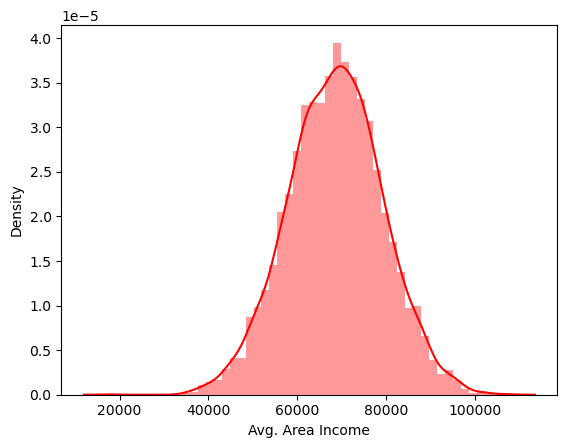

In [17]:
sns.distplot(df['Avg. Area Income'], color='r')
plt.show()

In [18]:
df['Avg. Area Income'].mean()

68583.10898395974

In [19]:
df['Avg. Area Income'].median()

68804.28640371616

In [20]:
# To fill missing value (Normal Distribution)

# df['Avg. Area Income'].fillna(df['Avg. Area Income'].mean(), inplace=True)

# Duplicate Data

In [21]:
df.duplicated().sum()

0

In [22]:
df[df.duplicated()]

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address


In [23]:
# To delete duplicate values

# df.drop_duplicates(keep='first')

# Outliers or Anomalies Detection and Treatment

## Using Boxplot

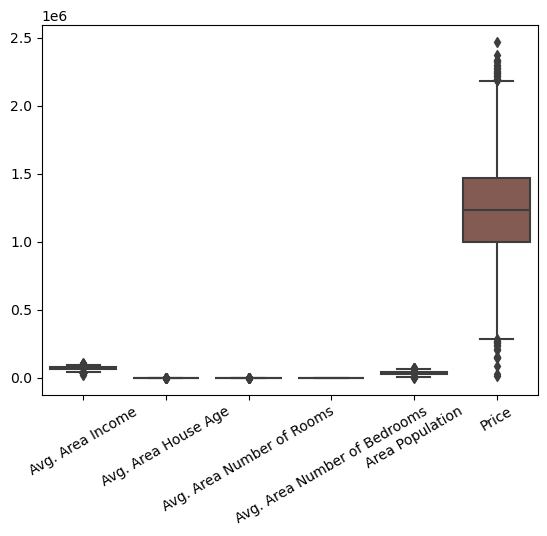

In [24]:
sns.boxplot(df)
plt.xticks(rotation=30)
plt.show()

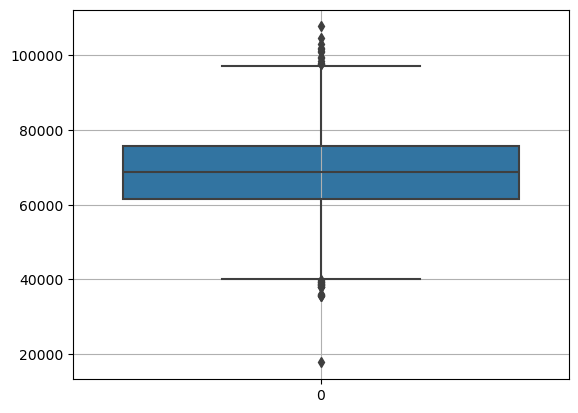

In [25]:
# plt.figure(figsize=(10, 12))
sns.boxplot(df['Avg. Area Income'])
plt.grid()
plt.show()

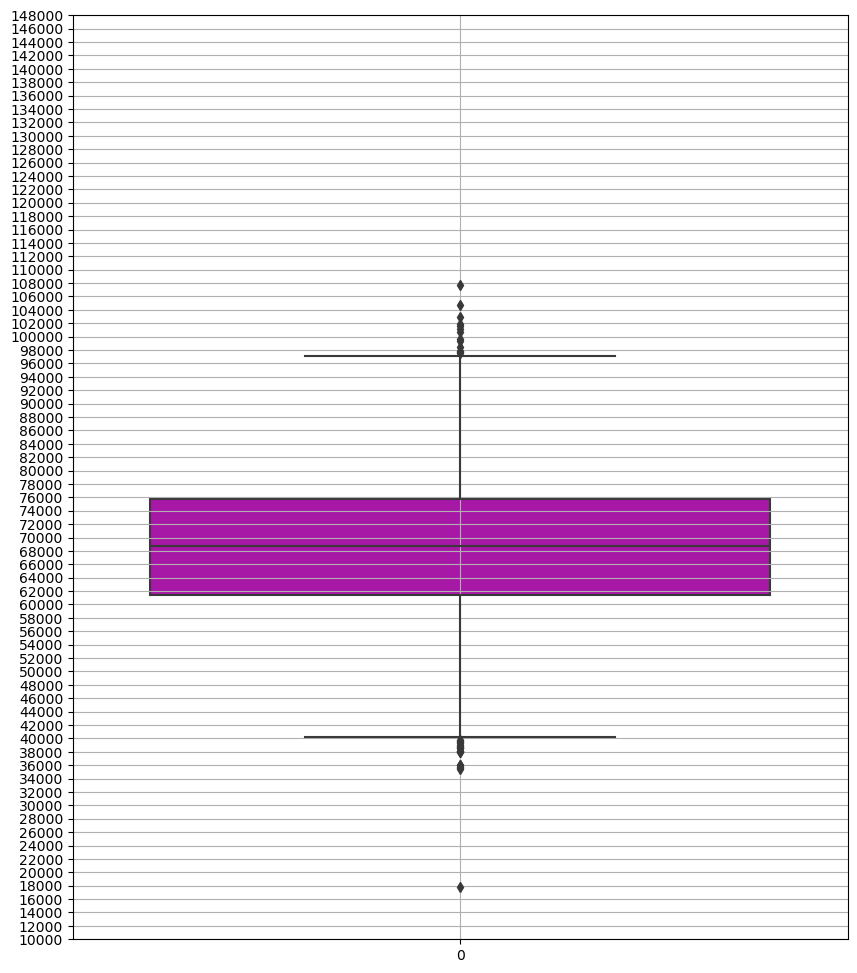

In [26]:
plt.figure(figsize=(10, 12))
sns.boxplot(df['Avg. Area Income'], color='m')
plt.yticks(np.arange(10000, 150000, 2000))
plt.grid()
plt.show()

In [27]:
len(df[df['Avg. Area Income'] > 97000])

15

In [28]:
len(df[df['Avg. Area Income'] < 40000])

19

In [29]:
len(df[(df['Avg. Area Income'] > 97000) | (df['Avg. Area Income'] < 40000)])

34

In [30]:
df[(df['Avg. Area Income'] > 97000) | (df['Avg. Area Income'] < 40000)]

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
12,39033.809237,7.671755,7.250029,3.10,39220.361467,1.042814e+06,"209 Natasha Stream Suite 961\nHuffmanland, NE ..."
39,17796.631190,4.949557,6.713905,2.50,47162.183643,3.023558e+05,"9932 Eric Circles\nLake Martha, WY 34611-6127"
411,36100.444227,5.778489,5.497450,2.29,44901.857338,5.995040e+05,"842 Duane Brook Apt. 380\nMonicaview, AR 01639..."
428,97112.361252,5.914725,6.133646,3.10,51470.067638,1.917584e+06,"35841 Christine Shore\nWallmouth, NC 98956-5357"
558,99629.013581,5.431863,7.351398,5.45,36950.739057,1.883481e+06,"PSC 0420, Box 6835\nAPO AE 08359"
693,107701.748378,7.143522,8.518608,3.29,37619.439929,2.332111e+06,"41017 Eric Village\nJonathanport, CO 37205"
844,39411.652788,4.385845,7.047435,4.44,45851.398296,5.394834e+05,"1085 Michele Glens Apt. 517\nSergiotown, VT 20367"
962,101928.858060,4.829586,9.039382,4.08,22804.991935,1.938866e+06,"856 Harris Centers Suite 940\nNicholasport, IL..."
1096,97548.310413,5.460973,6.609396,2.50,39089.415712,2.026303e+06,"349 Sean Forges\nWhitakerville, WY 85138-4153"
1271,37971.207566,4.291224,5.807510,3.24,33267.767728,3.114052e+04,"98398 Terrance Pines\nSouth Joshua, MT 00544-8919"


In [31]:
df[(df['Avg. Area Income'] > 97000) | (df['Avg. Area Income'] < 40000)].index

Index([  12,   39,  411,  428,  558,  693,  844,  962, 1096, 1271, 1459, 1597,
       1734, 1891, 2025, 2092, 2242, 2300, 2597, 2719, 3069, 3144, 3183, 3483,
       3541, 3798, 3947, 4087, 4400, 4449, 4716, 4744, 4844, 4855],
      dtype='int64')

In [32]:
df.shape

(5000, 7)

In [33]:
df.drop(index=[ 12,   39,  411,  428,  558,  693,  844,  962, 1096, 1271, 1459,
            1597, 1734, 1891, 2025, 2092, 2242, 2300, 2597, 2719, 3069, 3144,
            3183, 3483, 3541, 3798, 3947, 4087, 4400, 4449, 4716, 4744, 4844,
            4855], axis = 0, inplace=True)

In [34]:
df.shape

(4966, 7)

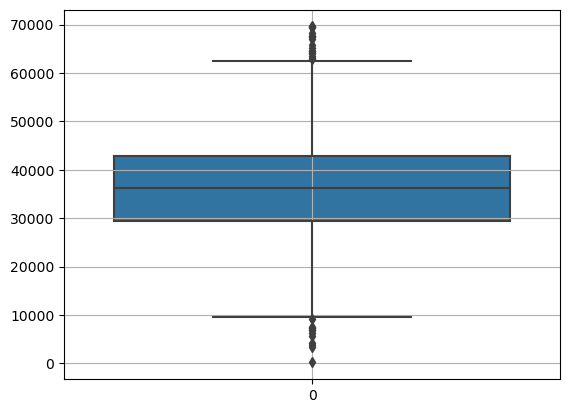

In [35]:
# plt.figure(figsize=(10, 12))
sns.boxplot(df['Area Population'])
plt.grid()
plt.show()

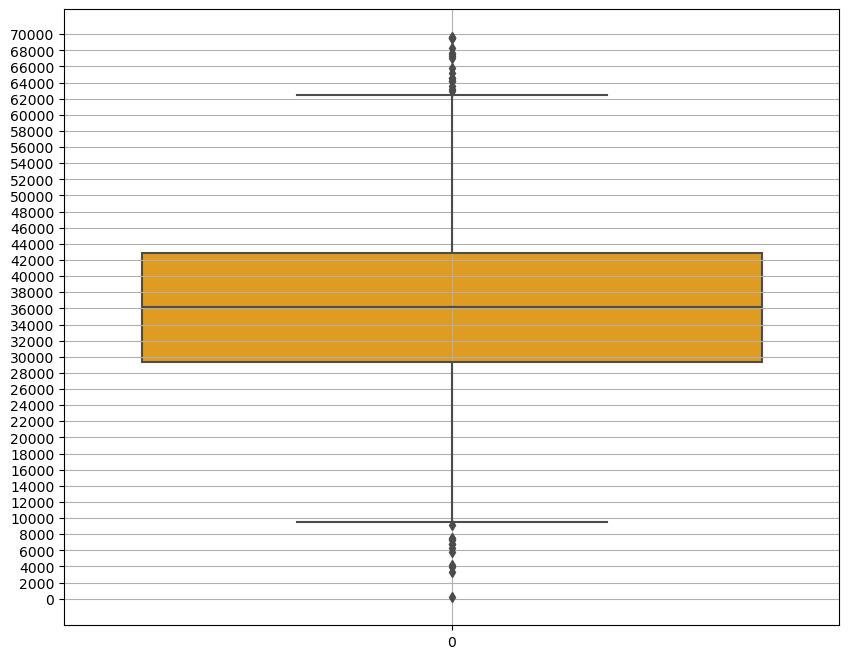

In [36]:
plt.figure(figsize=(10, 8))
sns.boxplot(df['Area Population'], color='orange')
plt.yticks(np.arange(0, 71000, 2000))
plt.grid()
plt.show()

In [37]:
len(df[df['Area Population'] > 63000])

17

In [38]:
len(df[df['Area Population'] < 10000])

15

In [39]:
len(df[(df['Area Population'] > 63000) | (df['Area Population'] < 10000)])

32

In [40]:
df[(df['Area Population'] > 63000) | (df['Area Population'] < 10000)]

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
105,81543.777315,5.503923,5.897053,2.14,9816.300885,9.541145e+05,Unit 5889 Box 7282\nDPO AE 41177-0399
228,66574.709994,5.550265,6.844150,2.17,69575.449464,1.702406e+06,"551 Macdonald Viaduct\nWest Stephanie, TN 55360"
314,68929.158074,7.590878,6.891969,3.24,172.610686,8.402729e+05,"178 John Fork Apt. 779\nEast James, VT 90132"
349,75312.259510,5.364982,6.667366,4.09,9487.921585,9.440016e+05,"004 Susan Lights Apt. 864\nEricstad, SD 18478"
353,72445.033303,5.488197,6.509449,2.48,69553.988327,1.726719e+06,"2763 Victoria Pine Apt. 066\nWest Stephanie, O..."
1234,63785.551276,7.196314,6.357874,4.50,67353.965204,1.747245e+06,USNV Roach\nFPO AA 76691
1361,55621.899104,3.735942,6.868291,2.30,63184.613147,1.102641e+06,"704 Davis Valleys Suite 264\nCollinstown, DE 6..."
1530,85175.200626,7.750852,7.271163,3.11,3285.450538,1.305972e+06,"792 Angela Forks\nSouth Tylerfort, WI 00472-1022"
1595,64350.284571,6.761203,7.128710,3.03,69592.040236,1.772391e+06,"48205 Bass Viaduct\nNorth Victormouth, VA 2652..."
1965,63884.926411,7.722146,5.791958,4.33,64566.687380,1.667561e+06,42051 Jeffrey Plaza Apt. 613\nEast Katelynview...


In [41]:
df[(df['Area Population'] > 63000) | (df['Area Population'] < 10000)].index

Index([ 105,  228,  314,  349,  353, 1234, 1361, 1530, 1595, 1965, 2108, 2173,
       2299, 2380, 2392, 2422, 2534, 2603, 2756, 2829, 2839, 3120, 3134, 3387,
       3442, 3540, 3991, 4182, 4290, 4491, 4684, 4803],
      dtype='int64')

In [42]:
df.drop(index = [ 105,  228,  314,  349,  353, 1234, 1361, 1530, 1595, 1965, 2108,
            2173, 2299, 2380, 2392, 2422, 2534, 2603, 2756, 2829, 2839, 3120,
            3134, 3387, 3442, 3540, 3991, 4182, 4290, 4491, 4684, 4803], axis=0, inplace=True)

In [43]:
df.shape

(4934, 7)

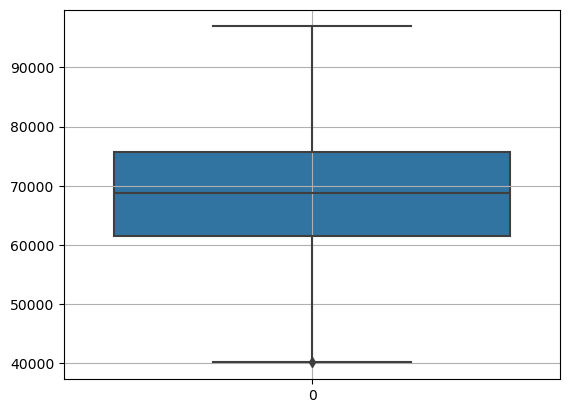

In [44]:
# plt.figure(figsize=(10, 12))
sns.boxplot(df['Avg. Area Income'])
plt.grid()
plt.show()

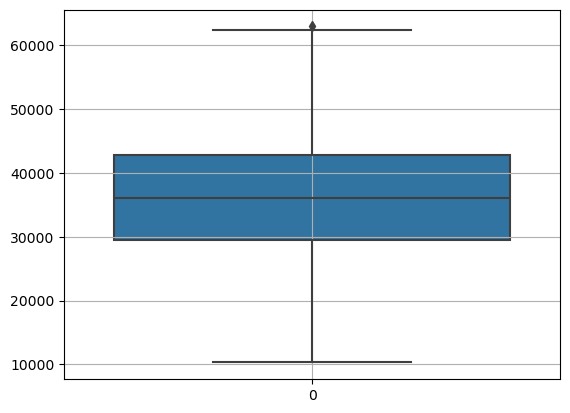

In [45]:
# plt.figure(figsize=(10, 12))
sns.boxplot(df['Area Population'])
plt.grid()
plt.show()

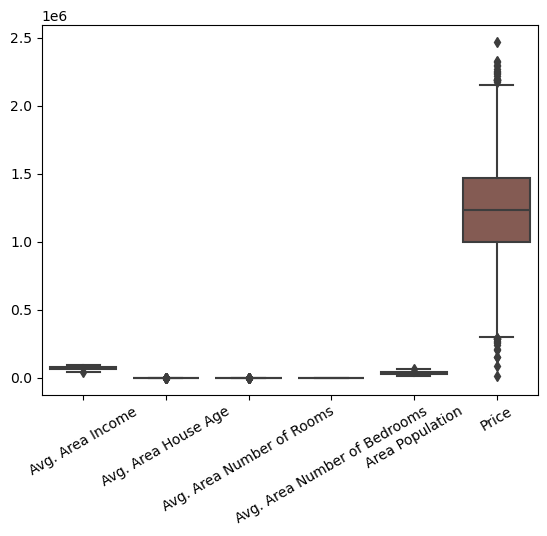

In [46]:
sns.boxplot(df)
plt.xticks(rotation=30)
plt.show()

# Feature Encoding

In [47]:
df.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05,USNS Raymond\nFPO AE 09386


In [48]:
df['Address'].nunique()

4934

In [49]:
 df.drop (columns=['Address'], axis=1, inplace=True)

In [50]:
df.shape

(4934, 6)

In [51]:
df.columns

Index(['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms',
       'Avg. Area Number of Bedrooms', 'Area Population', 'Price'],
      dtype='object')

# Histogram

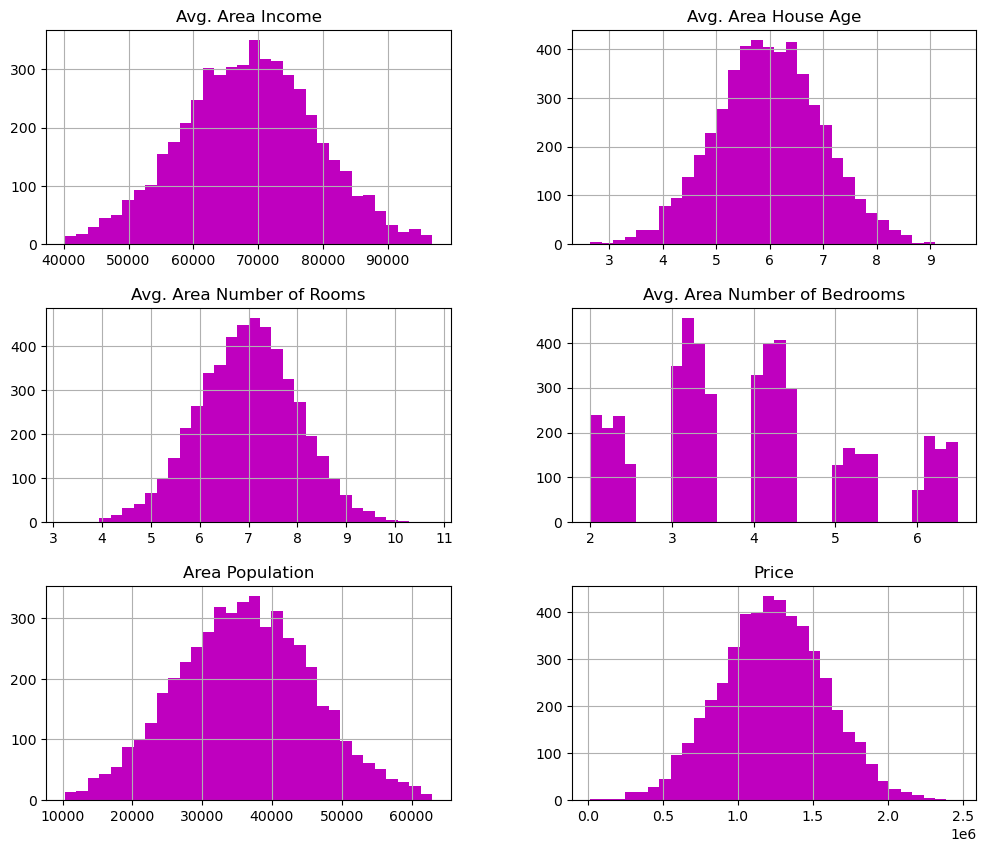

In [52]:
df.hist(figsize=(12, 10), bins=32, color='m')
plt.show()

# Feature Selection - Using Correlation Matrix 

In [53]:
df.corr()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
Avg. Area Income,1.000000,-0.006844,-0.012727,0.017680,-0.000916,0.635306
Avg. Area House Age,-0.006844,1.000000,-0.009100,0.003522,-0.017327,0.457466
Avg. Area Number of Rooms,-0.012727,-0.009100,1.000000,0.463195,0.001448,0.340396
Avg. Area Number of Bedrooms,0.017680,0.003522,0.463195,1.000000,-0.020661,0.172357
Area Population,-0.000916,-0.017327,0.001448,-0.020661,1.000000,0.409852
Price,0.635306,0.457466,0.340396,0.172357,0.409852,1.000000


<Axes: >

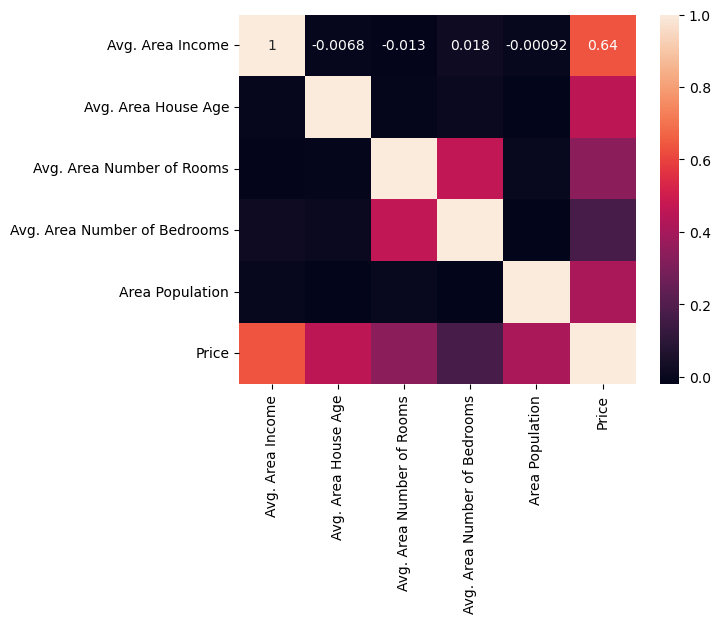

In [54]:
sns.heatmap(df.corr(), annot=True)

In [55]:
df.corr()['Price']

Avg. Area Income                0.635306
Avg. Area House Age             0.457466
Avg. Area Number of Rooms       0.340396
Avg. Area Number of Bedrooms    0.172357
Area Population                 0.409852
Price                           1.000000
Name: Price, dtype: float64

# Model Building using Regression Algorithm

In [56]:
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import xgboost
from xgboost import XGBRegressor

# Seprate your Independent and Dependent data

In [57]:
df.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05


In [58]:
X = df.iloc[:, :-1]
X

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population
0,79545.458574,5.682861,7.009188,4.09,23086.800503
1,79248.642455,6.002900,6.730821,3.09,40173.072174
2,61287.067179,5.865890,8.512727,5.13,36882.159400
3,63345.240046,7.188236,5.586729,3.26,34310.242831
4,59982.197226,5.040555,7.839388,4.23,26354.109472
...,...,...,...,...,...
4995,60567.944140,7.830362,6.137356,3.46,22837.361035
4996,78491.275435,6.999135,6.576763,4.02,25616.115489
4997,63390.686886,7.250591,4.805081,2.13,33266.145490
4998,68001.331235,5.534388,7.130144,5.44,42625.620156


In [59]:
y = df['Price']
y

0       1.059034e+06
1       1.505891e+06
2       1.058988e+06
3       1.260617e+06
4       6.309435e+05
            ...     
4995    1.060194e+06
4996    1.482618e+06
4997    1.030730e+06
4998    1.198657e+06
4999    1.298950e+06
Name: Price, Length: 4934, dtype: float64

# Data Splitting - Train and Test

In [60]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [61]:
X_train.shape, X_test.shape

((3947, 5), (987, 5))

In [62]:
y_train.shape, y_test.shape

((3947,), (987,))

In [63]:
X_train

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population
1172,71062.079568,7.187575,6.570481,4.41,30770.846815
1509,82321.731112,5.911488,6.813650,2.33,48616.264625
4130,84243.498335,6.210900,5.779485,2.19,30239.930756
4511,73921.635562,7.543492,5.880753,2.04,36269.232954
3105,52141.359009,7.567153,7.299796,3.28,29595.431430
...,...,...,...,...,...
4485,72466.080594,5.831391,5.670833,2.01,12113.114740
475,67461.446227,4.891103,8.002543,3.04,34573.112177
3136,65279.342591,4.470479,6.924874,4.39,29971.899764
3824,78693.840802,5.791574,6.453816,3.15,44210.155243


In [64]:
X_test

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population
422,82830.593527,5.933626,7.124917,4.13,32026.912253
3435,57316.042605,5.105172,6.986446,4.00,26121.144617
147,67946.714676,5.403176,5.671136,3.21,35197.942569
1197,78169.524692,5.540375,5.169303,3.32,44503.917406
3117,78788.439524,6.772487,6.637598,4.01,38656.431386
...,...,...,...,...,...
4287,78114.421334,7.570046,8.423978,6.00,41831.041117
1069,82185.469904,5.219918,5.343182,4.19,29258.988758
4690,84855.797423,5.488737,6.248574,4.07,37413.911418
3951,76228.513437,6.297774,8.402822,5.04,46694.142470


# Model Selection

### Using Linear Regression

In [65]:
lr = LinearRegression()
lr.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[ 21.59,165014.64,122042.88, 1668.12, 15.11]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['Avg. Area Income','Avg. Area House Age','Avg. Area Number of Rooms', 'Avg. Area Number of Bedrooms','Area Population']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2.641e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,5


In [66]:
print(f' Training Accuracy - {lr.score(X_train, y_train)}')
print(f' Test Accuracy     - {lr.score(X_test, y_test)}')

 Training Accuracy - 0.9159634531193421
 Test Accuracy     - 0.916716242833318


### Using Decision Tree Regressor

In [67]:
dt = DecisionTreeRegressor(max_depth=9)
dt.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",9
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes m

In [68]:
print(f' Training Accuracy - {dt.score(X_train, y_train)}')
print(f' Test Accuracy     - {dt.score(X_test, y_test)}')

 Training Accuracy - 0.920844221797021
 Test Accuracy     - 0.7861476730180096


### Using Gradient Boosting

In [69]:
gb = GradientBoostingRegressor(learning_rate=0.1, n_estimators=200)
gb.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",200
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"init in

In [70]:
print(f' Training Accuracy - {gb.score(X_train, y_train)}')
print(f' Test Accuracy     - {gb.score(X_test, y_test)}')

 Training Accuracy - 0.9337764423502012
 Test Accuracy     - 0.9020990496289729


### Using Xgboost Regressor

In [71]:
xgb = XGBRegressor(gamma=0.5, reg_alpha=0.6, reg_lambda=0.3)
xgb.fit(X_train, y_train)

,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None
,feature_types,None


In [72]:
print(f' Training Accuracy - {xgb.score(X_train, y_train)}')
print(f' Test Accuracy     - {xgb.score(X_test, y_test)}')

 Training Accuracy - 0.9851421546684724
 Test Accuracy     - 0.8781828895384317


#### As per the model prediction we will select Linear Regression as our final ML Algorithm for this problem statement.

Test Accuracy

- Linear Regression - 91%
- Gradient Boosting - 90%
- Xgboost Regressor - 87%
- Decision Tree     - 78%

In [73]:
# Linear Regression

In [74]:
lr = LinearRegression()
lr.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[ 21.59,165014.64,122042.88, 1668.12, 15.11]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['Avg. Area Income','Avg. Area House Age','Avg. Area Number of Rooms', 'Avg. Area Number of Bedrooms','Area Population']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2.641e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,5


In [75]:
y_pred_train = lr.predict(X_train)
y_pred_test = lr.predict(X_test)

In [76]:
lr.coef_

array([2.15886278e+01, 1.65014640e+05, 1.22042877e+05, 1.66811842e+03,
       1.51120822e+01])

In [77]:
X.columns

Index(['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms',
       'Avg. Area Number of Bedrooms', 'Area Population'],
      dtype='object')

In [78]:
coeff = pd.DataFrame(lr.coef_, index=X.columns, columns=['Coefficient'])
coeff

,Coefficient
Avg. Area Income,21.588628
Avg. Area House Age,165014.640161
Avg. Area Number of Rooms,122042.876698
Avg. Area Number of Bedrooms,1668.118423
Area Population,15.112082


In [79]:
X_train[:3]

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population
1172,71062.079568,7.187575,6.570481,4.41,30770.846815
1509,82321.731112,5.911488,6.813650,2.33,48616.264625
4130,84243.498335,6.210900,5.779485,2.19,30239.930756


In [80]:
y_train[:3]

1172    1.367143e+06
1509    1.574085e+06
4130    1.366668e+06
Name: Price, dtype: float64

In [81]:
y_pred_train[:3]

array([1352963.43287464, 1681359.54504608, 1368104.51408844])

In [82]:
# test

X_test[:3]

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population
422,82830.593527,5.933626,7.124917,4.13,32026.912253
3435,57316.042605,5.105172,6.986446,4.00,26121.144617
147,67946.714676,5.403176,5.671136,3.21,35197.942569


In [83]:
y_test[:3]

422     1.342246e+06
3435    6.231811e+05
147     1.043484e+06
Name: Price, dtype: float64

In [84]:
y_pred_test[:3]

array([1486289.05668242,  692393.32482508,  946397.16168641])

# Model Evaluation

In [85]:
# Training Data

In [86]:
def training_evaluation(actual, predicted):
    
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)
    r2 = r2_score(actual, predicted)
    
    
    print(f'MSE: {mse}')
    print(f'RMSE: {rmse}')    
    print(f'MAE: {mae}')    
    print(f'Accuracy: {r2}')    
    
    plt.scatter(y_train, y_pred_train, color='r', label='Actual Price')
    plt.plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 'k--', lw=2, label='Predicted Price')
    plt.title('Best-Fit Line using Linear Regression - Train')
    plt.xlabel('Actual Price')
    plt.ylabel('Predicted Price')
    plt.legend()
    plt.show()

MSE: 10230512274.178154
RMSE: 101145.99484991065
MAE: 81497.73347659907
Accuracy: 0.9159634531193421


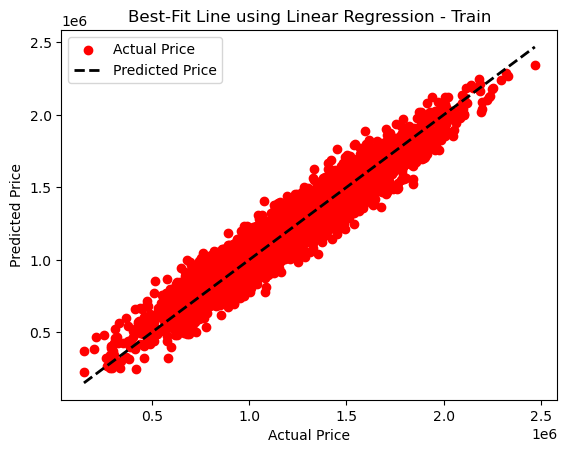

In [87]:
training_evaluation(y_train, y_pred_train)

In [88]:
# Test Data

In [89]:
def test_evaluation(actual, predicted):
    
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)
    r2 = r2_score(actual, predicted)
    
    
    print(f'MSE: {mse}')
    print(f'RMSE: {rmse}')    
    print(f'MAE: {mae}')    
    print(f'Accuracy: {r2}')    
    
    
    plt.scatter(y_test, y_pred_test, color='yellow', label='Actual Price')
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2, label='Predicted Price')
    plt.title('Best-Fit Line using Linear Regression - Test')
    plt.xlabel('Actual Price')
    plt.ylabel('Predicted Price')
    plt.legend()
    plt.show()

MSE: 9950044498.30073
RMSE: 99749.90976587763
MAE: 79996.77123135772
Accuracy: 0.916716242833318


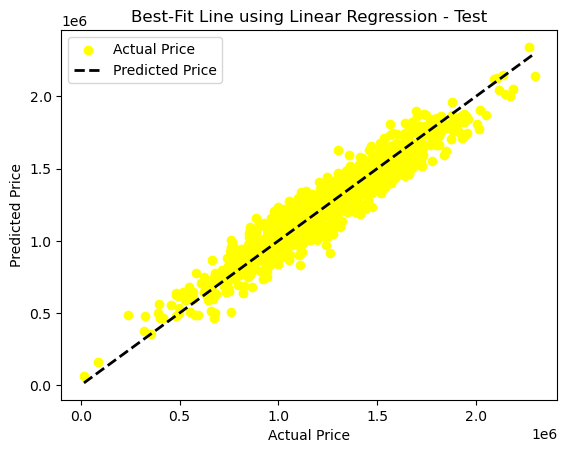

In [90]:
test_evaluation(y_test, y_pred_test)